<a href="https://colab.research.google.com/github/melaniee-sudo/machine-learning-udg-tareas/blob/main/p11_kmeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

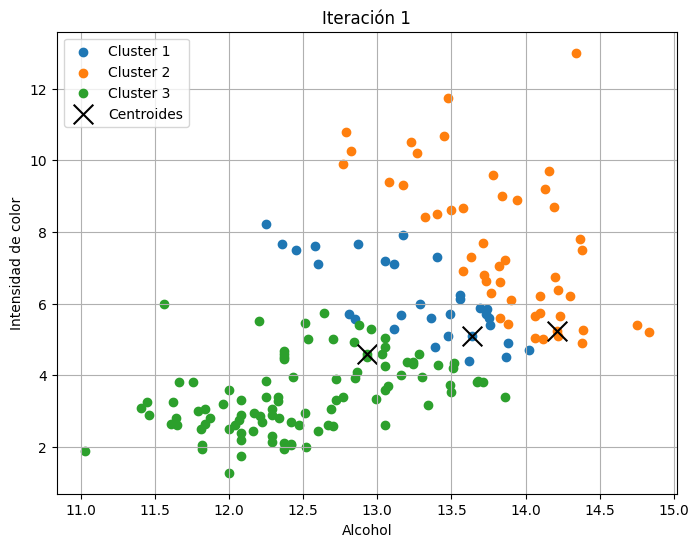

Iteración 1
Nuevos centroides:
[[13.27741935  6.09935484]
 [13.84530612  7.62673467]
 [12.49071429  3.44438776]]
------------------------


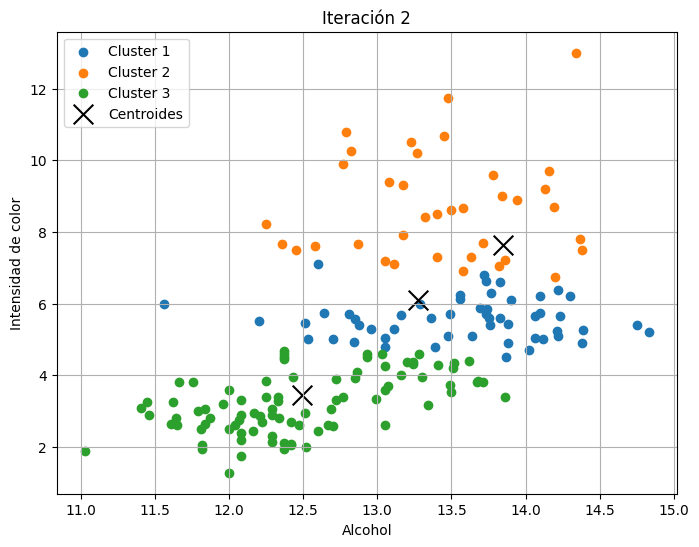

Iteración 2
Nuevos centroides:
[[13.55264151  5.56830189]
 [13.43324324  8.68675673]
 [12.48625     3.22511364]]
------------------------


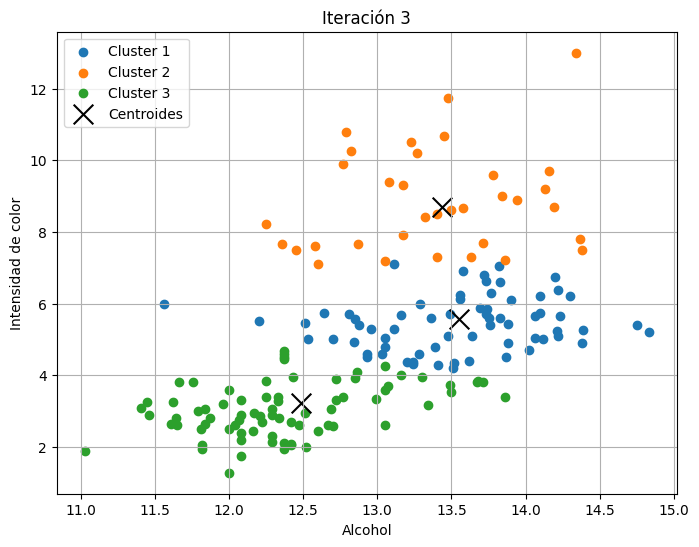

Iteración 3
Nuevos centroides:
[[13.52701493  5.43895522]
 [13.38        8.84441174]
 [12.37506494  3.05480519]]
------------------------


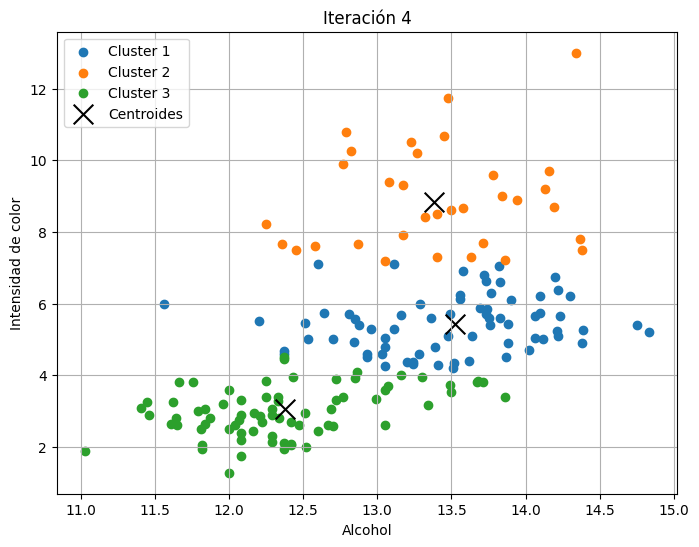

Iteración 4
Nuevos centroides:
[[13.47464789  5.42309859]
 [13.40363636  8.8972727 ]
 [12.36608108  2.99581081]]
------------------------


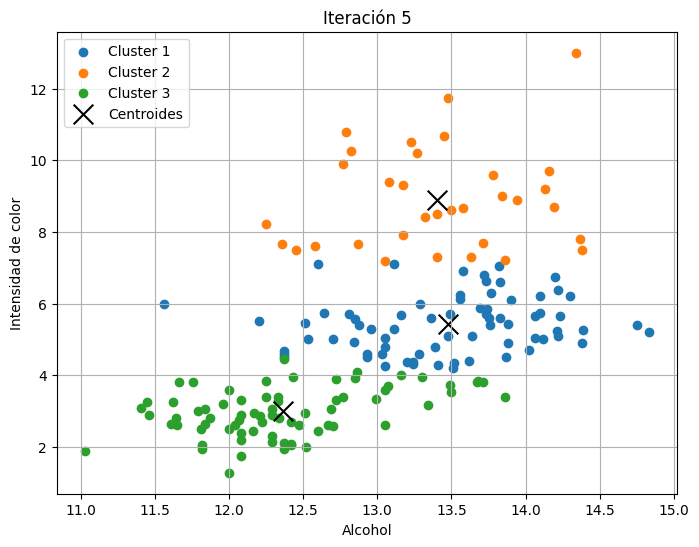

Iteración 5
Nuevos centroides:
[[13.45930556  5.41027778]
 [13.40363636  8.8972727 ]
 [12.3660274   2.97520548]]
------------------------


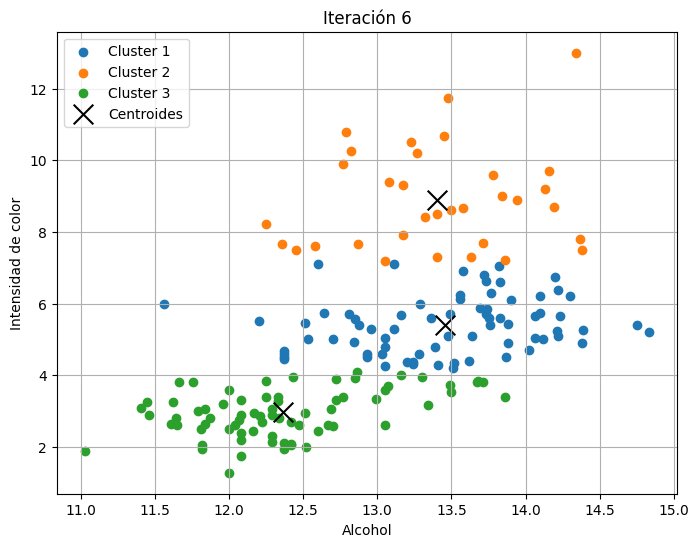

Iteración 6
Nuevos centroides:
[[13.44438356  5.39712329]
 [13.40363636  8.8972727 ]
 [12.36597222  2.95472222]]
------------------------


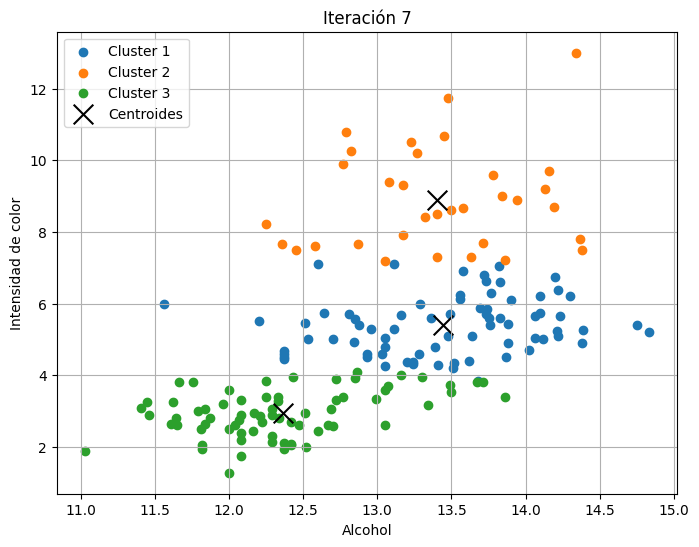

Iteración 7
Nuevos centroides:
[[13.44756757  5.37608108]
 [13.40363636  8.8972727 ]
 [12.34746479  2.94225352]]
------------------------


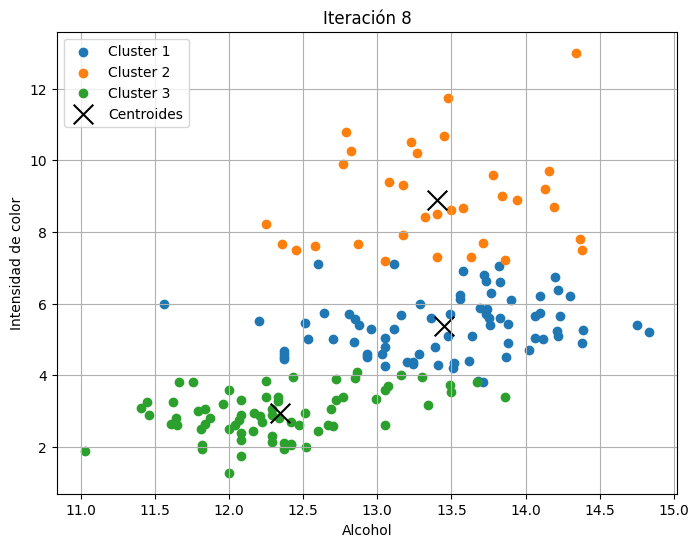

Iteración 8
Nuevos centroides:
[[13.45106667  5.35506667]
 [13.40363636  8.8972727 ]
 [12.328       2.93      ]]
------------------------


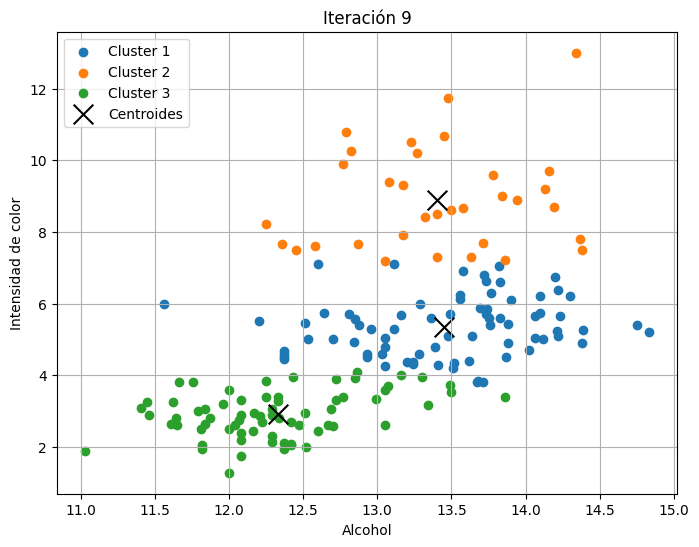

Iteración 9
Nuevos centroides:
[[13.45394737  5.33460526]
 [13.40363636  8.8972727 ]
 [12.30855072  2.9173913 ]]
------------------------


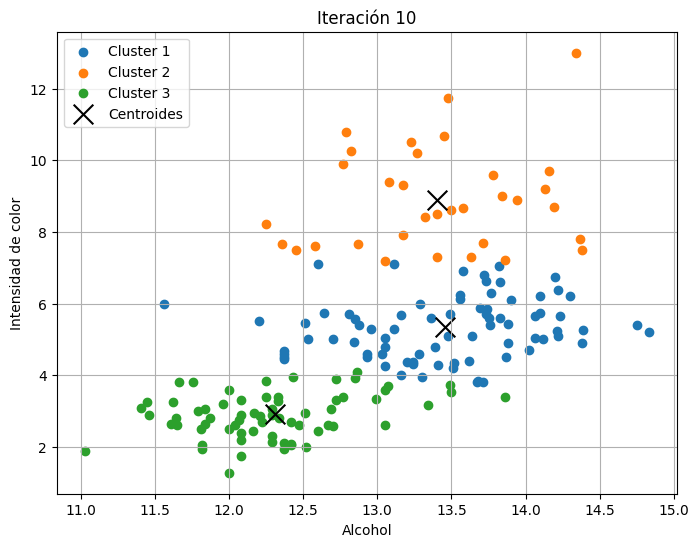

Iteración 10
Nuevos centroides:
[[13.44820513  5.29974359]
 [13.40363636  8.8972727 ]
 [12.28104478  2.8858209 ]]
------------------------
Proceso de K-Means finalizado.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#base de datos Wine
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine/wine.data"

columnas = [
    "clase", "alcohol", "malic_acid", "ash", "alcalinity_of_ash",
    "magnesium", "total_phenols", "flavanoids",
    "nonflavanoid_phenols", "proanthocyanins",
    "color_intensity", "hue", "od280_od315", "proline"
]

wine = pd.read_csv(url, names=columnas)

#Seleccionar dos atributos para visualizar los clusters
X = wine[["alcohol", "color_intensity"]].values

#funcion para calcular la distancia euclidiana
def distancia_euclidiana(punto1, punto2):
    suma_cuadrados = 0

    for i in range(len(punto1)):
        suma_cuadrados += (punto1[i] - punto2[i]) ** 2

    return np.sqrt(suma_cuadrados)


#inicializar los centroides aleatoriamente
k = 3
np.random.seed(42)

indices_aleatorios = np.random.choice(
    X.shape[0], k, replace=False
)

centroides = X[indices_aleatorios].copy()

colores = ["#1f77b4", "#ff7f0e", "#2ca02c"]

#realizar 10 iteraciones
num_iteraciones = 10

for iteracion in range(num_iteraciones):

    #asignar cada instancia al centroide mas cercano
    asignaciones = []

    for punto in X:
        distancias = []

        for centroide in centroides:
            dist = distancia_euclidiana(punto, centroide)
            distancias.append(dist)

        cluster_asignado = distancias.index(min(distancias))
        asignaciones.append(cluster_asignado)

    asignaciones = np.array(asignaciones)

    #visualizar los clusters de la iteracion
    plt.figure(figsize=(8, 6))

    for i in range(k):
        puntos_cluster = X[asignaciones == i]

        if len(puntos_cluster) > 0:
            plt.scatter(
                puntos_cluster[:, 0],
                puntos_cluster[:, 1],
                c=colores[i],
                label=f"Cluster {i+1}"
            )

    plt.scatter(
        centroides[:, 0],
        centroides[:, 1],
        c="black",
        marker="x",
        s=200,
        label="Centroides"
    )

    plt.title(f"Iteración {iteracion + 1}")
    plt.xlabel("Alcohol")
    plt.ylabel("Intensidad de color")
    plt.legend()
    plt.grid(True)
    plt.show()

    #actualizar los centroides
    nuevos_centroides = []

    for i in range(k):
        puntos_cluster = X[asignaciones == i]

        if len(puntos_cluster) > 0:
            nuevo_centroide = np.mean(
                puntos_cluster, axis=0
            )
            nuevos_centroides.append(nuevo_centroide)

        else:
            nuevos_centroides.append(centroides[i])

    centroides = np.array(nuevos_centroides)

    print(f"Iteración {iteracion + 1}")
    print("Nuevos centroides:")
    print(centroides)
    print("------------------------")

print("Proceso de K-Means finalizado.")
